# OFDM TX/RX — Pipeline robusta (HackRF) com detecção de runs inválidos + retries


## 1) Imports


In [2]:
import os, sys, time, json, subprocess, re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


## 2) Globais


In [3]:
WORKDIR = os.getcwd()

# Use serial (avoid hackrf=0/1 ambiguity)
TX_SERIAL = "0000000000000000147c63dc36507a53"
RX_SERIAL = "0000000000000000b36863dc23727e13"
TX_HACKRF = f"hackrf=0"
RX_HACKRF = f"hackrf=1"

# Lower default sample rate to reduce USB overflow on shared bus
SAMP_RATE = 2000000
CENTER_FREQ = 907980000.0

TX_PAYLOAD = os.path.join(WORKDIR, "tx_payload.bin")
RX_PAYLOAD = os.path.join(WORKDIR, "rx_payload.bin")
RX_IQ_FILE = os.path.join(WORKDIR, "rx_iq.cfile")

# Legacy known-payload mode (kept for quick sanity checks)
KNOWN_TEXT = "Hello World\n"
KNOWN_REPEATS = 200
KNOWN_MIN_COUNT = 5

# Benchmark mode (robust BER via packet pairing)
USE_BENCHMARK = True
BENCH_SEED = 12345
BENCH_NUM_PACKETS = 200
BENCH_PACKET_LEN = 50
BENCH_MAGIC = "OFDM"

# CRC: when enabled, RX only writes payload bytes for packets that pass CRC.
USE_CRC = False

# Validation thresholds
RX_MIN_BYTES = 500
MIN_MATCHED_PACKETS = 50

FATAL_STDERR_PATTERNS = [
    r"Buffer too small for min_noutput_items",
    r"thread_body_wrapper\s*:error",
]
OOOO_PATTERN = r"OOOO+"
WARN_STDERR_PATTERNS = [r"UUUU+"]

print("TX_PAYLOAD:", TX_PAYLOAD)
print("RX_PAYLOAD:", RX_PAYLOAD)

_RUNNER_PATH = os.path.join(WORKDIR, "ofdm_runner_crc_benchmark.py")


TX_PAYLOAD: /home/pesquisa/HEst_Prototyping/tx_payload.bin
RX_PAYLOAD: /home/pesquisa/HEst_Prototyping/rx_payload.bin


## 3) Gerar runner (script isolado TX+RX)


In [4]:
def stderr_has(patterns, stderr_text):
    for pat in patterns:
        if re.search(pat, stderr_text or "", flags=re.IGNORECASE):
            return True
    return False

def run_experiment_subprocess(
    seconds=6.0,
    noise_voltage=0.0,
    record_iq=False,
    tx_args=None,
    rx_args=None,
    use_crc=None,
    use_benchmark=None,
    samp_rate=None,
    seed=None,
    num_packets=None,
    packet_len=None,
    magic=None,
    extra_args=None,
):
    if tx_args is None:
        tx_args = TX_HACKRF
    if rx_args is None:
        rx_args = RX_HACKRF
    if use_crc is None:
        use_crc = USE_CRC
    if use_benchmark is None:
        use_benchmark = USE_BENCHMARK
    if samp_rate is None:
        samp_rate = SAMP_RATE

    cmd = [sys.executable, _RUNNER_PATH,
           "--seconds", str(seconds),
           "--noise_voltage", str(noise_voltage),
           "--tx_args", tx_args,
           "--rx_args", rx_args,
           "--samp_rate", str(samp_rate)]

    if use_crc:
        cmd.append("--use_crc")
    if record_iq:
        cmd.append("--record_iq")

    if use_benchmark:
        cmd.append("--use_benchmark")
        cmd.extend(["--seed", str(BENCH_SEED if seed is None else seed)])
        cmd.extend(["--num_packets", str(BENCH_NUM_PACKETS if num_packets is None else num_packets)])
        cmd.extend(["--packet_len", str(BENCH_PACKET_LEN if packet_len is None else packet_len)])
        cmd.extend(["--magic", str(BENCH_MAGIC if magic is None else magic)])
    else:
        # Legacy known payload for quick sanity checks
        cmd.extend(["--known_text", KNOWN_TEXT, "--known_repeats", str(KNOWN_REPEATS), "--write_known"])

    if extra_args:
        cmd.extend(extra_args)

    p = subprocess.run(cmd, capture_output=True, text=True)
    stdout = p.stdout
    stderr = p.stderr

    result = None
    for line in stdout.splitlines()[::-1]:
        line = line.strip()
        if not line:
            continue
        try:
            result = json.loads(line)
            break
        except Exception:
            continue

    return {"returncode": p.returncode, "stdout": stdout, "stderr": stderr, "result": result}

def validate_run(run):
    res = run.get("result")
    if res is None:
        return (False, "runner não retornou JSON")
    if run["returncode"] != 0:
        return (False, f"returncode != 0 ({run['returncode']})")
    if not res.get("ok", False):
        return (False, "runner capturou exceção ao rodar flowgraphs")

    stderr = run.get("stderr", "") or ""

    # Hard failures (always)
    if stderr_has(FATAL_STDERR_PATTERNS, stderr):
        return (False, "stderr contém erro fatal (buffer/thread)")

    rx_size = int(res.get("rx_size", 0) or 0)
    matched = res.get("matched_packets")
    matched = int(matched) if matched is not None else 0

    # If overflow happened, accept as warning only if decoding is still useful
    has_oooo = re.search(OOOO_PATTERN, stderr, flags=re.IGNORECASE) is not None
    if has_oooo:
        if (matched < MIN_MATCHED_PACKETS) or (rx_size < RX_MIN_BYTES):
            return (False, f"overflow (OOOO) e pouca decodificação útil (matched={matched}, rx_size={rx_size})")

    # Decoding usefulness checks
    if res.get("use_benchmark", False):
        if rx_size < RX_MIN_BYTES:
            return (False, f"rx_size muito pequeno ({rx_size})")
        if matched < MIN_MATCHED_PACKETS:
            return (False, f"matched_packets muito pequeno ({matched})")
    else:
        if rx_size < RX_MIN_BYTES:
            return (False, f"rx_size muito pequeno ({rx_size})")
        if int(res.get("known_pattern_count_in_rx_head", 0) or 0) < KNOWN_MIN_COUNT:
            return (False, f"padrão conhecido apareceu pouco (count={res.get('known_pattern_count_in_rx_head',0)})")

    if has_oooo:
        return (True, "válido (com warning: OOOO)")
    if stderr_has(WARN_STDERR_PATTERNS, stderr):
        return (True, "válido (com warning: UUUU)")
    return (True, "válido")

def run_with_retries(max_tries=5, sleep_between=0.1, **kwargs):
    last = None
    for k in range(1, max_tries+1):
        run = run_experiment_subprocess(**kwargs)
        last = run
        ok, reason = validate_run(run)
        print(f"[try {k}/{max_tries}] {reason}")
        if ok:
            run["validation_reason"] = reason
            return run
        time.sleep(sleep_between)
    last["validation_reason"] = "falhou após retries"
    return last


## 5) Sanity check (sem ruído) + diagnóstico (offset, BER alinhado)


In [5]:
def hexdump(b: bytes, n=64):
    b = b or b""
    h = " ".join(f"{x:02x}" for x in b[:n])
    a = "".join(chr(x) if 32 <= x < 127 else "." for x in b[:n])
    return f"{h}\n|{a}|"

def ber_bits(tx: bytes, rx: bytes):
    n = min(len(tx), len(rx))
    if n == 0:
        return None
    a = np.frombuffer(tx[:n], dtype=np.uint8)
    b = np.frombuffer(rx[:n], dtype=np.uint8)
    x = np.bitwise_xor(a, b)
    return float(np.unpackbits(x).sum()) / float(n * 8)

def safe_text(b: bytes, n=160):
    return (b or b"").decode("utf-8", errors="replace")[:n]


In [6]:
run0 = run_with_retries(
    max_tries=5,
    seconds=6.0,
    noise_voltage=0.0,
    record_iq=False,
    use_benchmark=USE_BENCHMARK,
    use_crc=USE_CRC,
    samp_rate=SAMP_RATE,
)
print("validation:", run0.get("validation_reason"))
print("stderr tail:")
print("\n".join((run0.get("stderr","") or "").splitlines()[-10:]))

res0 = run0.get("result")
print(json.dumps(res0, indent=2) if res0 else "<no result>")

if res0:
    print("use_crc:", res0.get("use_crc"), "use_benchmark:", res0.get("use_benchmark"))
    print("TX head hex:", res0.get("tx_head_hex"))
    print("RX head hex:", res0.get("rx_head_hex"))
    print("RX size:", res0.get("rx_size"), "TX size:", res0.get("tx_size"))

    if res0.get("use_benchmark"):
        print("rx_packets_parsed:", res0.get("rx_packets_parsed"))
        print("matched_packets:", res0.get("matched_packets"))
        print("missing_packets:", res0.get("missing_packets"))
        print("BER (por pacotes):", res0.get("ber_packets"))
    else:
        print("offset:", res0.get("offset"), "score:", res0.get("score"))
        print("BER bruto:", res0.get("ber_raw"))
        print("BER alinhado:", res0.get("ber_aligned"))


[try 1/5] válido (com warning: UUUU)
validation: válido (com warning: UUUU)
stderr tail:
gr-osmosdr 0.2.0.0 (0.2.0) gnuradio 3.10.11.0
built-in source types: file fcd rtl rtl_tcp uhd hackrf rfspace airspy soapy redpitaya 
Using HackRF One with firmware v2.0.1
gr-osmosdr 0.2.0.0 (0.2.0) gnuradio 3.10.11.0
built-in sink types: uhd hackrf soapy redpitaya file 
Using HackRF One with firmware v2.0.0
UUUU
{
  "ok": true,
  "seconds": 6.0,
  "noise_voltage": 0.0,
  "samp_rate": 2000000.0,
  "use_crc": false,
  "use_benchmark": true,
  "benchmark_seed": 12345,
  "benchmark_num_packets": 200,
  "benchmark_packet_len": 50,
  "benchmark_magic": "OFDM",
  "dt": 7.427645444869995,
  "tx_size": 10000,
  "rx_size": 220004,
  "tx_head_hex": "4f46444d000000006abb02d1d3cd4cda5eee3145906f295f1fdf6e428fa02c9c8d2f5abcf5bb1787fabc6995812a2534b8134f46444d0100000076ecbd7163e3",
  "rx_head_hex": "3fa7ad88c08776b6029892bfe07d4f46444d400000006abb02d1d3cd4cda5eee3145906f295f1fdf6e428fa02c9c8d2f5abcf5bb5787babc699

## 6) Varredura BER vs SNR (AWGN no RX) — repetição por ponto + retries


In [7]:
def snr_db_to_noise_voltage(snr_db):
    return 10 ** (-snr_db / 20.0)

def sweep(snr_db_list, seconds=6.0, repetitions=3, max_tries=5, use_crc=None, use_benchmark=None):
    if use_crc is None:
        use_crc = USE_CRC
    if use_benchmark is None:
        use_benchmark = USE_BENCHMARK

    rows = []
    for snr_db in snr_db_list:
        nv = snr_db_to_noise_voltage(snr_db)

        bers = []
        matcheds = []
        missings = []
        parsed = []
        valids = 0

        for _ in range(repetitions):
            run = run_with_retries(
                max_tries=max_tries,
                seconds=seconds,
                noise_voltage=nv,
                record_iq=False,
                use_crc=use_crc,
                use_benchmark=use_benchmark,
                samp_rate=SAMP_RATE,
            )
            ok, _ = validate_run(run)
            res = run.get("result") or {}
            if ok:
                valids += 1

            # Prefer robust benchmark metrics when enabled
            if use_benchmark:
                bers.append(res.get("ber_packets"))
                matcheds.append(res.get("matched_packets"))
                missings.append(res.get("missing_packets"))
                parsed.append(res.get("rx_packets_parsed"))
            else:
                bers.append(res.get("ber_aligned"))
                matcheds.append(np.nan)
                missings.append(np.nan)
                parsed.append(np.nan)

        bers_np = np.array([np.nan if b is None else b for b in bers], dtype=float)
        rows.append({
            "snr_db": snr_db,
            "noise_voltage": nv,
            "valid_runs": valids,
            "ber_mean": float(np.nanmean(bers_np)),
            "ber_std": float(np.nanstd(bers_np)),
            "matched_mean": float(np.nanmean(np.array(matcheds, dtype=float))),
            "missing_mean": float(np.nanmean(np.array(missings, dtype=float))),
            "rx_parsed_mean": float(np.nanmean(np.array(parsed, dtype=float))),
        })
    return rows


In [8]:
snr_db_list = [30, 25, 20, 15, 10, 5]
rows = sweep(snr_db_list, seconds=2, repetitions=5, max_tries=8, use_crc=USE_CRC, use_benchmark=USE_BENCHMARK)
rows


[try 1/8] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=0)
[try 2/8] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=0)
[try 3/8] válido (com warning: UUUU)
[try 1/8] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=23)
[try 2/8] válido (com warning: UUUU)
[try 1/8] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=0)
[try 2/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=43)
[try 2/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] overflow (OOOO) e pouca decodificação útil (matched=0, rx_size=0)
[try 2/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] válido (com warning: UUUU)
[try 1/8] overflow (OOOO

[{'snr_db': 30,
  'noise_voltage': 0.03162277660168379,
  'valid_runs': 5,
  'ber_mean': 0.04194571268665505,
  'ber_std': 0.0012987456025820442,
  'matched_mean': 188.4,
  'missing_mean': 11.6,
  'rx_parsed_mean': 1086.8},
 {'snr_db': 25,
  'noise_voltage': 0.05623413251903491,
  'valid_runs': 5,
  'ber_mean': 0.03940420569689298,
  'ber_std': 0.0012917283860502972,
  'matched_mean': 188.4,
  'missing_mean': 11.6,
  'rx_parsed_mean': 1082.0},
 {'snr_db': 20,
  'noise_voltage': 0.1,
  'valid_runs': 5,
  'ber_mean': 0.04002329108658401,
  'ber_std': 0.005038518620335801,
  'matched_mean': 186.8,
  'missing_mean': 13.2,
  'rx_parsed_mean': 1064.4},
 {'snr_db': 15,
  'noise_voltage': 0.1778279410038923,
  'valid_runs': 5,
  'ber_mean': 0.03865996847370914,
  'ber_std': 0.006201329357131306,
  'matched_mean': 187.2,
  'missing_mean': 12.8,
  'rx_parsed_mean': 1040.6},
 {'snr_db': 10,
  'noise_voltage': 0.31622776601683794,
  'valid_runs': 5,
  'ber_mean': 0.05219871417071591,
  'ber_std': 

## 7) Gráficos finais


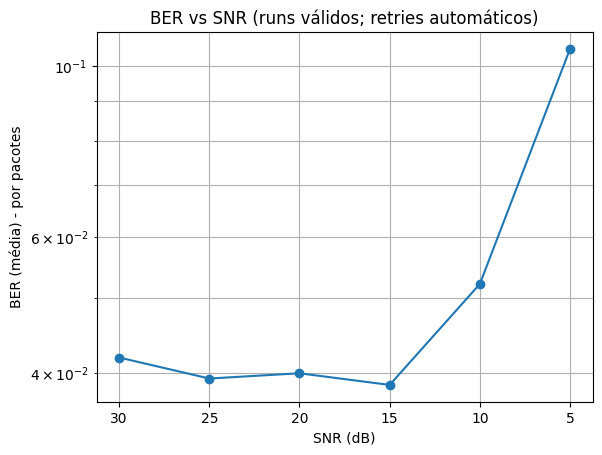

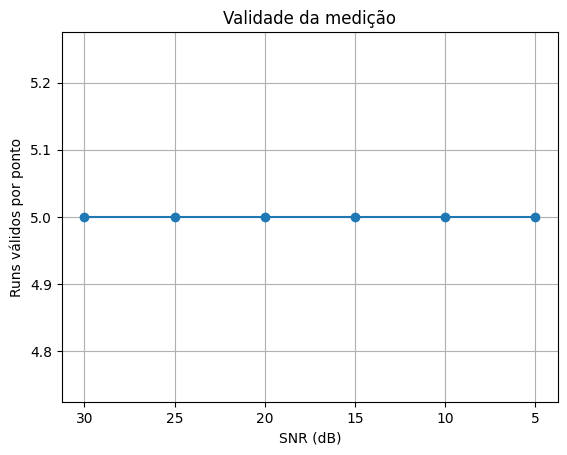

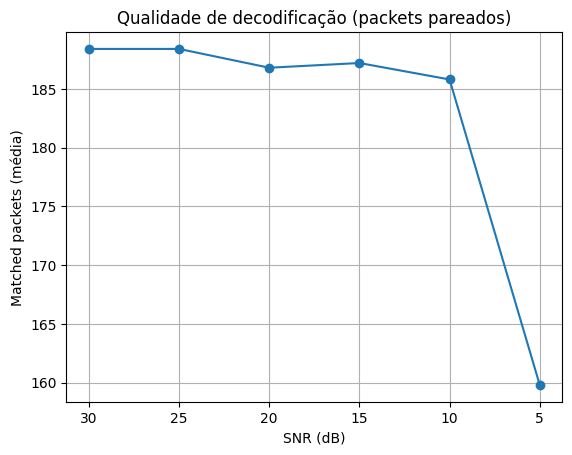

In [9]:
snr = [r["snr_db"] for r in rows]
ber = [r["ber_mean"] for r in rows]
valids = [r["valid_runs"] for r in rows]
matched = [r["matched_mean"] for r in rows]

plt.figure()
plt.semilogy(snr, ber, marker="o")
plt.gca().invert_xaxis()
plt.grid(True, which="both")
plt.xlabel("SNR (dB)")
plt.ylabel("BER (média) - por pacotes" if USE_BENCHMARK else "BER (alinhado) - média")
plt.title("BER vs SNR (runs válidos; retries automáticos)")
plt.show()

plt.figure()
plt.plot(snr, valids, marker="o")
plt.gca().invert_xaxis()
plt.grid(True)
plt.xlabel("SNR (dB)")
plt.ylabel("Runs válidos por ponto")
plt.title("Validade da medição")
plt.show()

if USE_BENCHMARK:
    plt.figure()
    plt.plot(snr, matched, marker="o")
    plt.gca().invert_xaxis()
    plt.grid(True)
    plt.xlabel("SNR (dB)")
    plt.ylabel("Matched packets (média)")
    plt.title("Qualidade de decodificação (packets pareados)")
    plt.show()
